<a href="https://colab.research.google.com/github/unknxwNS/Ihopeitworks/blob/main/%D0%9C%D1%96%D1%85%D0%B0%D0%BB%D1%8C%D0%BE%D0%B2_%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [ ]:
# TODO: підрахуйте частоти категорій у gender.
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [ ]:
# TODO: підрахуйте частоти категорій у smoking_history.
print(df['smoking_history'].value_counts())

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [ ]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [ ]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [ ]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [ ]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [ ]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [ ]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

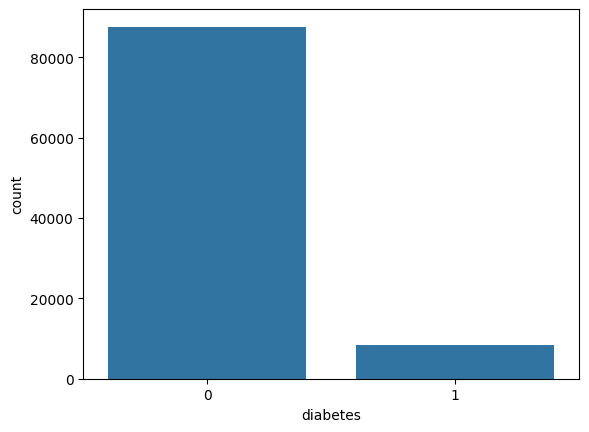

In [ ]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.

# Створюємо X (ознаки) та y (цільова змінна)
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Розділяємо дані на навчальну та тестову вибірки у пропорції 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

# Закодовуємо категоріальні ознаки
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], dtype=int)

# Вирівнюємо стовпці тестової вибірки відповідно до навчальної
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [ ]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
correlations = X_train.corrwith(y_train).sort_values(ascending=False)
print(correlations)

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
gender_Female                 -0.040533
smoking_history_No Info       -0.113053
dtype: float64


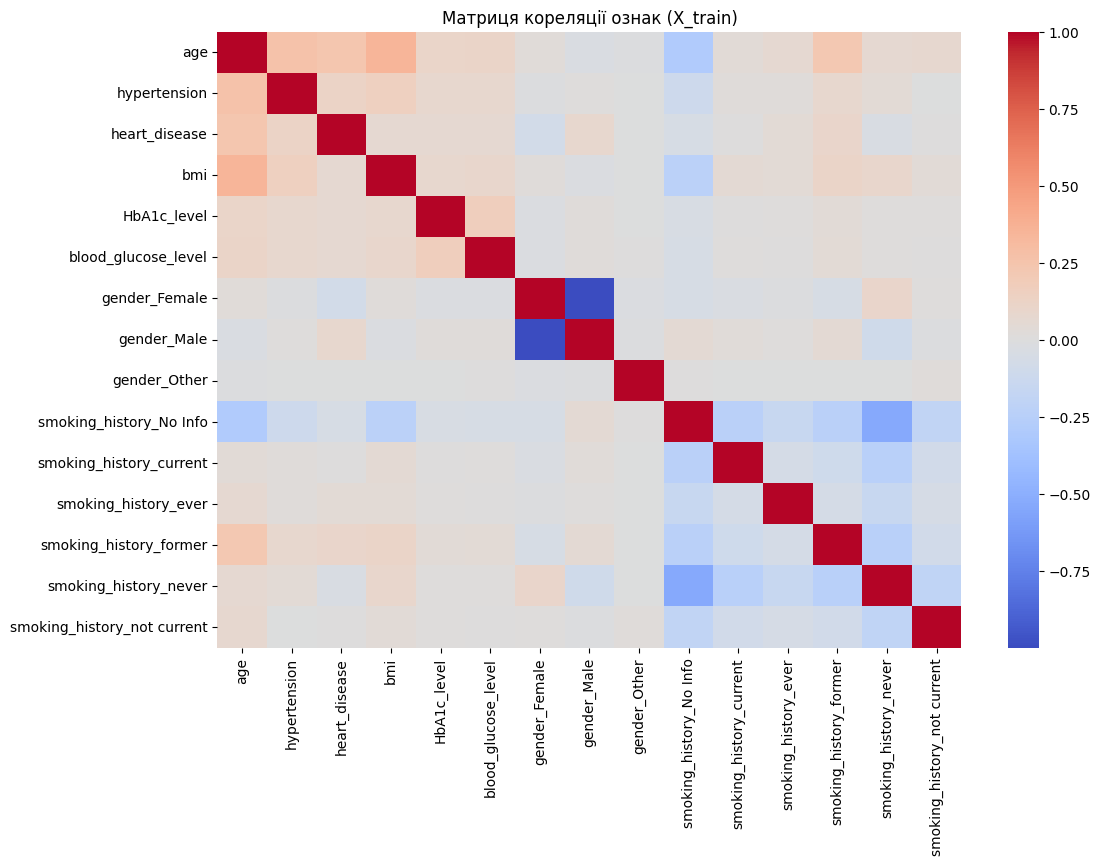

In [ ]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

corr_matrix = X_train.corr()

# Будуємо теплову карту кореляцій
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title('Матриця кореляції ознак (X_train)')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Висновок:

За результатами аналізу можна визначити ознаки, які найбільше корелюють між собою та з цільовою змінною diabetes. Сильно корельовані ознаки можуть містити схожу інформацію, але видаляти їх необов’язково. Рішення про видалення ознак слід приймати з урахуванням їхньої важливості для моделі. Аналіз проводився лише на навчальних даних, без використання тестової вибірки.

Перевірити викиди **лише на навчальній вибірці**

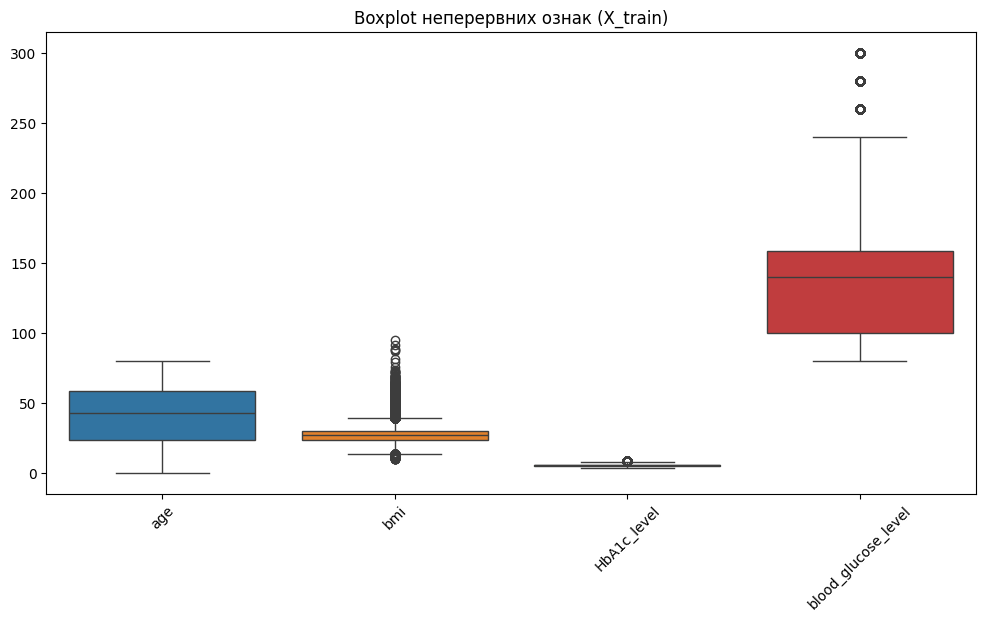

In [ ]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

# Вибираємо неперервні ознаки
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# Будуємо boxplot для пошуку викидів на навчальній вибірці
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Boxplot неперервних ознак (X_train)')
plt.xticks(rotation=45)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

# Межі для виявлення викидів обчислюються лише на X_train
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# У цій роботі викиди не видаляємо

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].

print(X_train[continuous_cols].skew())

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [ ]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Пропуски в X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never  

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Висновок:

У навчальній вибірці було перевірено співвідношення класів, кореляції між ознаками та наявність викидів. Якщо класи розподілені нерівномірно, це може впливати на якість прогнозування діабету. Викиди не видаляли, оскільки вони можуть містити важливу інформацію. Тестову вибірку не змінювали, щоб зберегти об’єктивність оцінювання моделі.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.

# Створюємо об'єкт для масштабування ознак
scaler = StandardScaler()

# Навчаємо scaler на train і масштабуємо навчальні дані
X_train_scaled = scaler.fit_transform(X_train)

# Масштабуємо тестові дані за параметрами train
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

# Перевіряємо кількість об'єктів кожного класу до балансування
print("До SMOTE:")
print(y_train.value_counts())

# Балансуємо лише навчальну вибірку
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

# Перевіряємо кількість об'єктів після балансування
print("\nПісля SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

До SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [ ]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

# Оголошуємо моделі для класифікації
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Ridge Classifier': RidgeClassifier(),
    'SGD Classifier': SGDClassifier(random_state=42),
    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



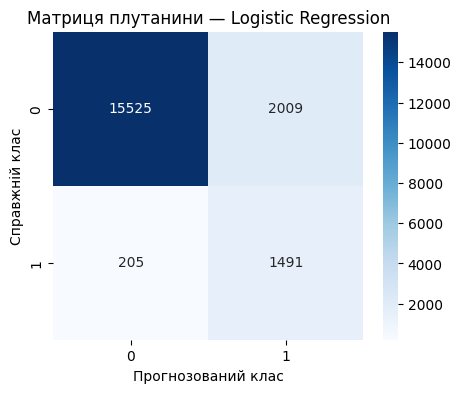


Модель: Ridge Classifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



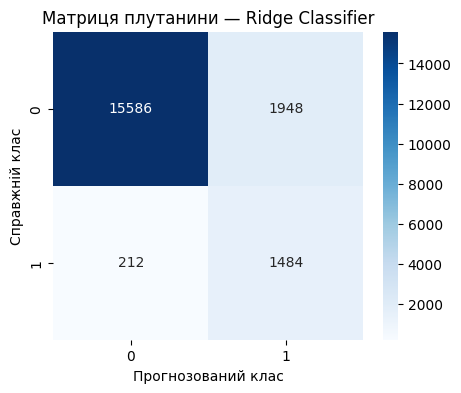


Модель: SGD Classifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



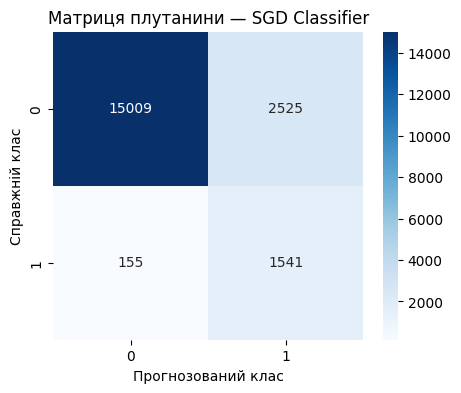


Модель: SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



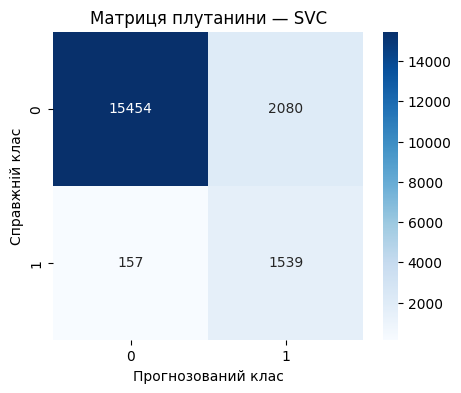

In [ ]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

for name, model in models.items():
    # Навчаємо модель на збалансованій навчальній вибірці
    model.fit(X_train_balanced, y_train_balanced)

    # Робимо прогноз на тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Виводимо класифікаційний звіт
    print(f"\nМодель: {name}")
    print(classification_report(y_test, y_pred))

    # Будуємо матрицю плутанини
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Матриця плутанини — {name}')
    plt.xlabel('Прогнозований клас')
    plt.ylabel('Справжній клас')
    plt.show()

In [ ]:
print("До SMOTE:", X_train_scaled.shape)
print("После SMOTE:", X_train_balanced.shape)

До SMOTE: (76916, 15)
После SMOTE: (140260, 15)


Оптимізувати гіперпараметри


In [ ]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier


models = {
    'Logistic Regression': LogisticRegression(
        max_iter=300,
        random_state=42
    ),
    'Ridge Classifier': RidgeClassifier(),
    'SGD Classifier': SGDClassifier(
        random_state=42,
        max_iter=1000,
        tol=1e-3
    )
}

param_grids = {
    'Logistic Regression': {
        'C': [0.1, 1]
    },
    'Ridge Classifier': {
        'alpha': [0.1, 1, 10]
    },
    'SGD Classifier': {
        'loss': ['hinge', 'log_loss'],
        'alpha': [0.001, 0.0001]
    }
}

best_models = {}
results = {}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"\nПідбір параметрів: {name}", flush=True)

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring='f1_macro',
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train_balanced, y_train_balanced)

    best_models[name] = grid_search.best_estimator_
    results[name] = grid_search.best_score_

    print("Найкращі параметри:", grid_search.best_params_)
    print("F1-macro:", round(grid_search.best_score_, 4))

print("\nПорівняння моделей:")
for name, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"{name}: F1-macro = {score:.4f}")


Підбір параметрів: Logistic Regression
Fitting 2 folds for each of 2 candidates, totalling 4 fits
Найкращі параметри: {'C': 0.1}
F1-macro: 0.8875

Підбір параметрів: Ridge Classifier
Fitting 2 folds for each of 3 candidates, totalling 6 fits
Найкращі параметри: {'alpha': 0.1}
F1-macro: 0.888

Підбір параметрів: SGD Classifier
Fitting 2 folds for each of 4 candidates, totalling 8 fits
Найкращі параметри: {'alpha': 0.001, 'loss': 'hinge'}
F1-macro: 0.8895

Порівняння моделей:
SGD Classifier: F1-macro = 0.8895
Ridge Classifier: F1-macro = 0.8880
Logistic Regression: F1-macro = 0.8875


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

import pandas as pd

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Моделі та їхні набори параметрів
model_configs = {
    'Logistic Regression': (
        LogisticRegression(max_iter=500, random_state=42),
        {
            'model__C': [0.1, 1, 10]
        }
    ),
    'Ridge Classifier': (
        RidgeClassifier(),
        {
            'model__alpha': [0.1, 1, 10]
        }
    ),
    'SGD Classifier': (
        SGDClassifier(random_state=42, max_iter=1000, tol=1e-3),
        {
            'model__loss': ['hinge', 'log_loss'],
            'model__alpha': [0.001, 0.0001]
        }
    )
}

best_models = {}
best_scores = {}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for name, (estimator, param_grid) in model_configs.items():
    print(f"\nПідбір параметрів: {name}", flush=True)

    # Масштабування та SMOTE виконуються всередині кожного train-fold
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, k_neighbors=3)),
        ('model', estimator)
    ])

    search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring='f1',
        cv=cv,
        factor=3,
        min_resources=3000,
        max_resources=15000,
        resource='n_samples',
        n_jobs=-1,
        verbose=1,
        random_state=42
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("Найкращі параметри:", search.best_params_)
    print("Найкращий F1:", round(search.best_score_, 4))

print("\nПорівняння моделей:")
for name, score in sorted(best_scores.items(), key=lambda item: item[1], reverse=True):
    print(f"{name}: F1 = {score:.4f}")


Підбір параметрів: Logistic Regression
n_iterations: 2
n_required_iterations: 2
n_possible_iterations: 2
min_resources_: 3000
max_resources_: 15000
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 3
n_resources: 3000
Fitting 3 folds for each of 3 candidates, totalling 9 fits
----------
iter: 1
n_candidates: 1
n_resources: 9000
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Найкращі параметри: {'model__C': 1}
Найкращий F1: 0.6032

Підбір параметрів: Ridge Classifier
n_iterations: 2
n_required_iterations: 2
n_possible_iterations: 2
min_resources_: 3000
max_resources_: 15000
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 3
n_resources: 3000
Fitting 3 folds for each of 3 candidates, totalling 9 fits
----------
iter: 1
n_candidates: 1
n_resources: 9000
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Найкращі параметри: {'model__alpha': 10}
Найкращий F1: 0.5945

Підбір параметрів: SGD Classifier
n_iterations: 2
n_requi

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

# Вибираємо модель із найвищим середнім F1 на крос-валідації
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print("Найкраща модель:", best_model_name)
print("Середній F1 на крос-валідації:", round(best_scores[best_model_name], 4))

Найкраща модель: Logistic Regression
Середній F1 на крос-валідації: 0.6032


In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

# Вибираємо 10 випадкових індексів тестової вибірки
random_indices = X_test.sample(n=10, random_state=42).index

# Отримуємо фактичні класи та прогнози моделі
X_sample = X_test.loc[random_indices]
y_true = y_test.loc[random_indices]
y_pred = best_model.predict(X_sample)

# Формуємо таблицю результатів
results_df = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас': y_true.values,
    'Передбачений клас': y_pred
})

display(results_df)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?




1. У даних спостерігався дисбаланс класів. Кореляційний аналіз показав зв’язки між ознаками, а перевірка викидів допомогла виявити нетипові значення.

2. Було порівняно три моделі: Logistic Regression, Ridge Classifier та SGD Classifier. Найкращу модель визначено за середнім F1 на крос-валідації.

3. Гіперпараметри підбиралися для покращення результатів. Матриця плутанини показала правильні прогнози та помилки моделей.

4. Тестові дані не використовувалися під час навчання, щоб об’єктивно оцінити модель. Масштабування та SMOTE застосовували лише до навчальних даних, щоб уникнути витоку інформації.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [ ]:
!pip install -q xgboost lightgbm catboost


Модель: XGBoost
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.46      0.93      0.61      1696

    accuracy                           0.90     19230
   macro avg       0.72      0.91      0.78     19230
weighted avg       0.95      0.90      0.91     19230



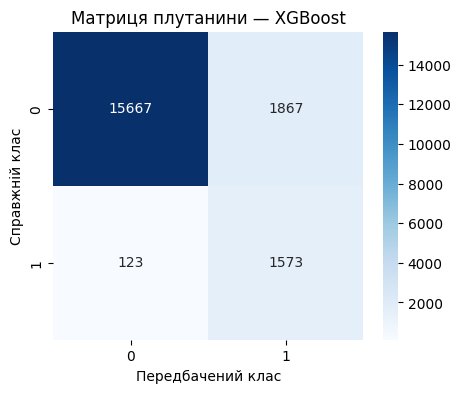


Модель: LightGBM
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.46      0.92      0.61      1696

    accuracy                           0.90     19230
   macro avg       0.72      0.91      0.78     19230
weighted avg       0.94      0.90      0.91     19230



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


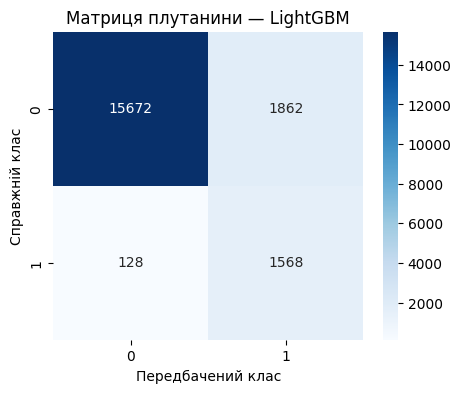


Модель: CatBoost
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.46      0.92      0.61      1696

    accuracy                           0.90     19230
   macro avg       0.72      0.91      0.78     19230
weighted avg       0.94      0.90      0.91     19230



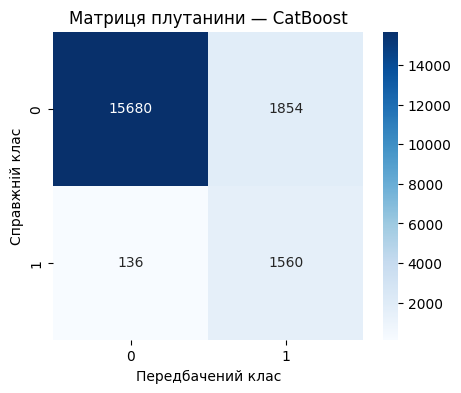

In [ ]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
import matplotlib.pyplot as plt
import seaborn as sns

# Створюємо моделі
models_extra = {
    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),
    'CatBoost': CatBoostClassifier(
        iterations=100,
        depth=5,
        learning_rate=0.1,
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
}

# Враховуємо дисбаланс класів без SMOTE
sample_weights = compute_sample_weight('balanced', y_train)

for name, model in models_extra.items():
    print(f'\n{"=" * 45}\nМодель: {name}')

    # Навчання на масштабованих даних
    model.fit(X_train_scaled, y_train, sample_weight=sample_weights)

    # Прогноз на тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Класифікаційний звіт
    print(classification_report(y_test, y_pred, zero_division=0))

    # Матриця плутанини
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Матриця плутанини — {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Справжній клас')
    plt.show()

Висновок:

Під час роботи було порівняно моделі XGBoost, LightGBM та CatBoost для прогнозування діабету. Усі моделі показали точність близько 90%, а Recall для класу діабету становив 92–93%. Найкращий Recall показала XGBoost, яка виявила найбільшу кількість випадків діабету. Отже, усі три моделі продемонстрували схожі результати, але XGBoost трохи краще виявляє людей із діабетом.